# A dated plan on real history: \$10,000, \$500 a month, two windfalls, then withdrawals, in the dogs of the S&P 500 against the index

A plan is more than a starting amount. Money goes in on dates, some of it in lumps, and from some date money comes out. This notebook runs one such plan on 33 years of real S&P 500 history, with the library's `plan` and `plan_montecarlo` operations: \$10,000 invested on 2 January 1990, \$500 a month after that indexed to inflation (CPI), two extraordinary investments (\$25,000 in March 1999 and \$15,000 in March 2009), and withdrawals of \$3,000 a month from January 2018. The strategy is the dogs of the S&P 500 (the ten highest trailing dividend yields in the index, renewed every year). The question is what the same dollars on the same days would have become in the dogs and in the index, in a TFSA, an RRSP and a taxable account, how that compares by every measure the plan reports, and how much of the result was the strategy and how much was the order of the returns.

**LOCAL USE ONLY.** The data is for local use only. The panel is an unlicensed, mixed-source dataset (CRSP-derived for 1968-2006, then Yahoo, Tiingo and Quandl WIKI prices) that you download yourself with `make data-panel` into the git-ignored folder `screenlab/data/panel/`. It is not part of this repository and is not redistributed; do not commit or share the files, or outputs that embed them.

**The base case in every chart and table is to buy and hold the S&P 500 (its total return, dividends included) with the same dollars on the same days, in the same account, taxed the same way.** It is the grey dashed line, labelled "Buy and hold the index", and the row labelled "Buy and hold the index" in every table. The numbers describe one historical path under the 2025 Canadian tax tables, with US CPI and the US 10-year yield standing in for Canadian series (Section 7); they are not a forecast. Not tax advice. Nothing is written to disk and nothing leaves your machine. The notebook takes about two and a half minutes to run once the panel is cached (the first call adds a minute while the market snapshots are built).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Lab
from screenlab.plan import CashFlow
from screenlab.realdata import sp500_panel
from screenlab.taxes import CanadianTax, TaxConfig
from screenlab.research import plan_plots as pp
from screenlab.research import tax_plots as tp

if not sp500_panel.available():
    raise RuntimeError("The S&P 500 panel is not on this machine: run `make data-panel` once (local use only), then run this notebook again.")

%matplotlib inline
plt.rcParams["figure.dpi"] = 80
ACCOUNTS = ["tfsa", "rrsp", "taxable"]
NAME = tp.ACCOUNT_NAME                    # tfsa -> TFSA, rrsp -> RRSP, taxable -> Taxable
STRAT = "dogs"
DOGS_LABEL, INDEX_LABEL = "Dogs of the S&P 500", "Buy and hold the index"
START, END = "1990-01-01", "2022-12-30"
FIRST = "1990-01-02"
GOAL = 1_500_000                          # nominal dollars, after tax
N_PATHS = 500
WINDFALLS = [CashFlow("1999-03-01", 25_000, "windfall 1999"), CashFlow("2009-03-01", 15_000, "windfall 2009")]

def show(fig):
    display(fig); plt.close(fig)

def say(text):                            # a paragraph written from the run's own numbers, so it cannot drift from them
    display(Markdown(text))

def usd(v):                               # dollars, with the dollar sign escaped so markdown does not read it as maths
    return f"\\${v:,.0f}"

def sd(v):                                # signed dollars
    return ("+" if v >= 0 else "-") + f"\\${abs(v):,.0f}"

def pc(v):                                # a fraction as a percent
    return f"{100 * v:.2f}%"

def pts(v):                               # a fraction as points a year
    return f"{100 * v:.2f}"

def mult(a, b):                           # a as a multiple of b
    return f"{a / b:.1f}"

In [2]:
# All the runs of the notebook, once, so the summary can quote every number it uses.
lab = Lab.real_sp500(start=START, end=END)          # the point-in-time panel; the cached load takes a few seconds

def tax_config(account, other_income=90_000, rrsp_rate=0.30):
    # other_income: what you earn from work each year; it sets the bracket the portfolio's income is stacked on
    return TaxConfig(model=CanadianTax("AB", other_income=other_income), macro=lab.macro, account=account,
                     rrsp_withdrawal_rate=rrsp_rate)

PLAN = dict(end=END, initial=10_000, periodic=500, frequency="monthly", growth="cpi", extra=WINDFALLS, withdrawals=3_000,
            withdraw_from="2018-01-01", goal=GOAL, rebalance_months=12)
plans = {a: lab.plan(STRAT, FIRST, tax=tax_config(a), **PLAN) for a in ACCOUNTS}          # the straight calculation, three accounts
hold = lab.plan(STRAT, FIRST, tax=tax_config("tfsa"), cash_timing="hold", **PLAN)         # contributions wait in cash until the next rebalance
from screenlab.montecarlo import plan_mc
mcs = {a: plan_mc.plan_montecarlo(lab, plans[a].spec, n_paths=N_PATHS, seed=1, result=plans[a]) for a in ("tfsa", "taxable")}   # the straight runs are not repeated
replays = {a: plan_mc.plan_montecarlo(lab, plans[a].spec, n_paths=2, generator="history", result=plans[a]) for a in ACCOUNTS}   # the recorded months in their own order
card = plans["tfsa"].card

def m(a, row, col):                      # one metric of one account's plan: row strategy | index | difference
    return plans[a].metrics.loc[row, col]

FL = plans["tfsa"].flows
FL = FL[FL["applied"]].copy()
FL["executed"] = pd.to_datetime(FL["executed"])
GROSS_IN = FL.loc[FL["amount"] > 0, "amount"].sum()
OUT = -FL.loc[FL["amount"] < 0, "amount"].sum()
NET = GROSS_IN - OUT
N_PER = int((FL["kind"] == "periodic").sum())
PER = FL.loc[FL["kind"] == "periodic", "amount"]
assert abs(NET - m("tfsa", "strategy", "Contributed")) < 1e-6 and N_PER == 336
S = {a: plans[a].series for a in ACCOUNTS}

def first_date(series, level):            # first day the series is at or above `level`
    hit = series[series >= level]
    return hit.index[0] if len(hit) else None

In [3]:
# The summary. Every number below is read from the runs above.
t = plans["tfsa"]
reached = {(a, w): first_date(S[a][f"{w}_after_tax"], GOAL) for a in ACCOUNTS for w in ("strategy", "index")}
yrs_goal = {(a, w): m(a, w, "YearsToGoal") for a in ACCOUNTS for w in ("strategy", "index")}
cost_hold = m("tfsa", "strategy", "FinalAfterTax") - hold.metrics.loc["strategy", "FinalAfterTax"]
mt, mx = mcs["tfsa"], mcs["taxable"]
REPLAY = {(a, w): float(replays[a].terminal[f"{w}_after_tax"].iloc[0]) for a in ACCOUNTS for w in ("strategy", "index")}
assert all(abs(REPLAY[a, w] - m(a, w, "FinalAfterTax")) <= 1e-6 * m(a, w, "FinalAfterTax") for a in ACCOUNTS for w in ("strategy", "index"))
MC_FWD = REPLAY["tfsa", "strategy"]                                  # the history replayed through the Monte Carlo = the straight run
HIST_PCT = float((mt.terminal["strategy_after_tax"] < MC_FWD).mean())
say(f'''
## Summary

**What the plan produced.** Between January 1990 and December 2022 the plan put {usd(GROSS_IN)} into the market ({usd(PLAN["initial"])} at the start, {N_PER} monthly contributions that grew with CPI from {usd(PER.iloc[0])} to {usd(PER.iloc[-1])}, and two windfalls of {usd(WINDFALLS[0].amount)} and {usd(WINDFALLS[1].amount)}) and took {usd(OUT)} back out from January 2018, so the net money in was {usd(NET)}. In the dogs of the S&P 500 the same dollars on the same days finished at {usd(m("tfsa", "strategy", "FinalPreTax"))} before tax; after tax they finished at {usd(m("tfsa", "strategy", "FinalAfterTax"))} in a TFSA, {usd(m("rrsp", "strategy", "FinalAfterTax"))} in an RRSP (withdrawal taxed at 30%) and {usd(m("taxable", "strategy", "FinalAfterTax"))} in a taxable account (Alberta, other income \\$90,000), against {usd(m("tfsa", "index", "FinalAfterTax"))}, {usd(m("rrsp", "index", "FinalAfterTax"))} and {usd(m("taxable", "index", "FinalAfterTax"))} for buying and holding the index ({usd(m("tfsa", "index", "FinalPreTax"))} before tax). The money-weighted return (XIRR) of the dogs was {pc(m("tfsa", "strategy", "XIRR"))} a year before tax and {pc(m("tfsa", "strategy", "XIRRAfterTaxReal"))} after tax and inflation in the TFSA, against {pc(m("tfsa", "index", "XIRR"))} and {pc(m("tfsa", "index", "XIRRAfterTaxReal"))} for the index. The lead came with more risk: alpha {pc(m("tfsa", "strategy", "Alpha"))} a year and beta {m("tfsa", "strategy", "Beta"):.2f}, but volatility of {pc(m("tfsa", "strategy", "Vol"))} against {pc(m("tfsa", "index", "Vol"))}, a Sharpe ratio of {m("tfsa", "strategy", "Sharpe"):.2f} against {m("tfsa", "index", "Sharpe"):.2f}, and a worst fall of {pc(-m("tfsa", "strategy", "MaxDD"))} against {pc(-m("tfsa", "index", "MaxDD"))}.

**What it means for the goal and the risk.** After tax the dogs first held {usd(GOAL)} on {reached["tfsa", "strategy"]:%d %B %Y} in the TFSA ({yrs_goal["tfsa", "strategy"]:.1f} years in) and the index on {reached["tfsa", "index"]:%d %B %Y} ({yrs_goal["tfsa", "index"]:.1f} years). Keeping each contribution in cash until the next yearly rebalance, instead of investing it on the next trading day, would have cost {usd(cost_hold)} of the TFSA's final after-tax wealth. On {N_PATHS} resampled paths of the same 33 years the dogs finished ahead of the index after tax on {pc(mt.p_beat_index)} of paths in the TFSA and {pc(mx.p_beat_index)} in the taxable account, and ended below the {usd(GOAL)} goal on {pc(mt.p_shortfall)} and {pc(mx.p_shortfall)} of paths (the index: {pc(mt.p_shortfall_index)} and {pc(mx.p_shortfall_index)}). The range of outcomes is wide: the dogs' TFSA final on the resampled paths has a median of {usd(mt.quantiles.loc[50, "strategy_after_tax"])} and a 5th to 95th percentile range from {usd(mt.quantiles.loc[5, "strategy_after_tax"])} to {usd(mt.quantiles.loc[95, "strategy_after_tax"])}, and the historical order, replayed through the Monte Carlo, reproduces the straight run's {usd(MC_FWD)} to the dollar, at the {100 * HIST_PCT:.0f}th percentile of those paths.
''')


## Summary

**What the plan produced.** Between January 1990 and December 2022 the plan put \$295,904 into the market (\$10,000 at the start, 336 monthly contributions that grew with CPI from \$500 to \$953, and two windfalls of \$25,000 and \$15,000) and took \$180,000 back out from January 2018, so the net money in was \$115,904. In the dogs of the S&P 500 the same dollars on the same days finished at \$4,036,691 before tax; after tax they finished at \$2,611,567 in a TFSA, \$2,825,735 in an RRSP (withdrawal taxed at 30%) and \$1,294,278 in a taxable account (Alberta, other income \$90,000), against \$1,558,015, \$1,172,391 and \$1,203,998 for buying and holding the index (\$1,674,844 before tax). The money-weighted return (XIRR) of the dogs was 12.84% a year before tax and 8.34% after tax and inflation in the TFSA, against 9.18% and 6.27% for the index. The lead came with more risk: alpha 4.97% a year and beta 1.06, but volatility of 25.10% against 15.00%, a Sharpe ratio of 0.46 against 0.41, and a worst fall of 83.37% against 55.28%.

**What it means for the goal and the risk.** After tax the dogs first held \$1,500,000 on 13 November 2013 in the TFSA (23.9 years in) and the index on 02 September 2020 (30.7 years). Keeping each contribution in cash until the next yearly rebalance, instead of investing it on the next trading day, would have cost \$217,764 of the TFSA's final after-tax wealth. On 500 resampled paths of the same 33 years the dogs finished ahead of the index after tax on 73.60% of paths in the TFSA and 60.60% in the taxable account, and ended below the \$1,500,000 goal on 24.40% and 45.60% of paths (the index: 42.00% and 54.40%). The range of outcomes is wide: the dogs' TFSA final on the resampled paths has a median of \$3,312,717 and a 5th to 95th percentile range from \$383,026 to \$25,832,062, and the historical order, replayed through the Monte Carlo, reproduces the straight run's \$2,611,567 to the dollar, at the 44th percentile of those paths.


## 1. The flows

The first question is what the plan does with money, and when. Every later number depends on it, because a return on a dollar that arrived in year 28 means something different from a return on a dollar that arrived in year 1, and a dollar taken out in 2018 is a dollar that stops compounding. The plan has four kinds of flow: the lump sum on the first day, a monthly contribution that starts at \$500 and grows with US CPI, two dated windfalls, and from January 2018 a fixed \$3,000 a month withdrawal; contributions stop on the day the withdrawals start. A flow dated on a non-trading day executes on the next trading day, and the passive index receives exactly the same dollars on exactly the same days, less a 0.05% yearly fund fee.

Figure 1 shows the dollars that went in and out in each calendar year as bars, by kind, and the running net total (contributions less withdrawals) as a line. The dashed grey line is the base case: the money the index is fed is the same, so it lies exactly on the strategy's.

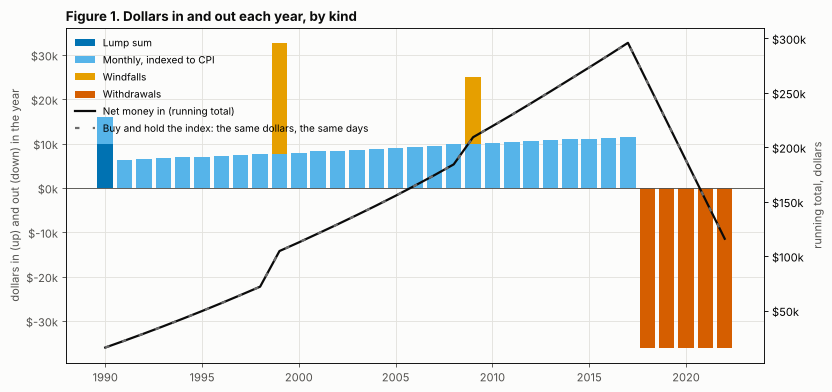

Table 1. The plan's flows, 1990-2022 (the index receives the same flows)


,Flows,Dollars
Lump sum,1,"$10,000"
"Monthly, indexed to CPI",336,"$245,904"
Windfalls,2,"$40,000"
Withdrawals,60,"$-180,000"
Net money in (the same for the index),399,"$115,904"


In [4]:
kinds = {"initial": ("Lump sum", tp.PALETTE[0]), "periodic": ("Monthly, indexed to CPI", tp.PALETTE[4]),
         "extra": ("Windfalls", tp.AMBER), "withdrawal": ("Withdrawals", tp.PALETTE[1])}
by = FL.assign(year=FL["executed"].dt.year).pivot_table(index="year", columns="kind", values="amount", aggfunc="sum")
by = by.reindex(columns=list(kinds)).fillna(0.0)
fig, ax = plt.subplots(figsize=(10.5, 5))
tp._ax(ax)
bottom_pos = np.zeros(len(by)); bottom_neg = np.zeros(len(by))
for k, (name, col) in kinds.items():
    v = by[k].to_numpy()
    base = bottom_pos if k != "withdrawal" else bottom_neg
    ax.bar(by.index, v, bottom=base, color=col, width=0.8, label=name)
    if k != "withdrawal":
        bottom_pos = bottom_pos + v
    else:
        bottom_neg = bottom_neg + v
net = S["tfsa"]["contributed"].resample("YE").last()
ax2 = ax.twinx()
ax2.plot(net.index.year, net.to_numpy(), color=tp.INK, lw=2, label="Net money in (running total)")
ax2.plot(net.index.year, net.to_numpy(), color=tp.INDEX_COL, lw=2, ls="--", dashes=(2, 6), label="Buy and hold the index: the same dollars, the same days")
ax2.set_ylabel("running total, dollars", color=tp.INK2)
ax2.yaxis.set_major_formatter(lambda v, _: f"${v / 1e3:.0f}k")
ax.yaxis.set_major_formatter(lambda v, _: f"${v / 1e3:.0f}k")
ax.set_ylabel("dollars in (up) and out (down) in the year")
ax.axhline(0, color=tp.INK2, lw=0.8)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=9, loc="upper left", frameon=False)
ax.set_title("Figure 1. Dollars in and out each year, by kind", loc="left", fontsize=12, fontweight="bold", color=tp.INK)
fig.tight_layout(); show(fig)

tab1 = pd.DataFrame({"Flows": FL.groupby("kind").size().reindex(list(kinds)), "Dollars": FL.groupby("kind")["amount"].sum().reindex(list(kinds))})
tab1.index = [kinds[k][0] for k in tab1.index]
tab1.loc["Net money in (the same for the index)"] = [len(FL), FL["amount"].sum()]
print("Table 1. The plan's flows, 1990-2022 (the index receives the same flows)")
tab1.style.format({"Flows": "{:,.0f}", "Dollars": "${:,.0f}"})

In [5]:
# how long the average dollar was invested: each contribution weighted by the years it stayed in until the end of 2022
end_ts = pd.Timestamp(END)
yrs_in = (end_ts - FL["executed"]).dt.days / 365.25
con = FL[FL["amount"] > 0]
AVG_AGE = float((con["amount"] * (end_ts - con["executed"]).dt.days / 365.25).sum() / con["amount"].sum())
WINDOW = (end_ts - pd.Timestamp(FIRST)).days / 365.25
LATE = con.loc[con["executed"] >= "2005-01-01", "amount"].sum() / con["amount"].sum()
say(f'''
### What the evidence says

The plan is back-loaded. Of the {usd(GROSS_IN)} that went in, {pc(LATE)} went in after 2004, and {usd(OUT)} came out in the last five years, so the net {usd(NET)} is small beside the {WINDOW:.1f} years the window spans. Weighted by dollars, the average contribution was invested for {AVG_AGE:.1f} years, not {WINDOW:.1f}, and the two windfalls ({usd(WINDFALLS[0].amount + WINDFALLS[1].amount)}, {pc((WINDFALLS[0].amount + WINDFALLS[1].amount) / GROSS_IN)} of the money in) arrived in March 1999, on the way up to the dot-com peak, and in March 2009, the month of the financial-crisis low. That timing is why a money-weighted return and the return of one dollar left alone for 33 years differ in Section 3, and why the same dollars in the index are the fair base case: both sides receive them on the same days, so any gap is the strategy's and not the schedule's.
''')
assert AVG_AGE < WINDOW - 5 and abs(NET - (GROSS_IN - OUT)) < 1e-6


### What the evidence says

The plan is back-loaded. Of the \$295,904 that went in, 50.51% went in after 2004, and \$180,000 came out in the last five years, so the net \$115,904 is small beside the 33.0 years the window spans. Weighted by dollars, the average contribution was invested for 18.4 years, not 33.0, and the two windfalls (\$40,000, 13.52% of the money in) arrived in March 1999, on the way up to the dot-com peak, and in March 2009, the month of the financial-crisis low. That timing is why a money-weighted return and the return of one dollar left alone for 33 years differ in Section 3, and why the same dollars in the index are the fair base case: both sides receive them on the same days, so any gap is the strategy's and not the schedule's.


## 2. The straight calculation: wealth against the money put in

The question for this section is simple: what were the contributions worth at the end, in the dogs and in the index, before and after tax, and in which account? The calculation follows each dollar. A contribution on a trading day buys the dogs' current ten names in equal weights (paying the library's trading cost, 25 basis points a side), a withdrawal sells pro rata, the yearly rebalance renews the ten highest yields, and the dividends are reinvested. The index leg buys the S&P 500 total return less the 0.05% fund fee. Tax is paid from the portfolio, as in every other backtest of the library: at each year's last trading day the year's tax is sold out of the holdings (pro rata, so the cost base shrinks with them), and the last year's tax, the tax on the gains realized at the end and, in the RRSP, 30% of the balance (the withdrawal rate for the whole pot) come out on the last day. The after-tax line is the wealth the investor would actually have held, so it cannot go below zero, and the pre-tax line is the same plan with no tax at all.

Figure 2 draws the plan in each account on a logarithmic scale. In each panel the dotted black line is the net money put in, the thin lines are wealth before tax and the thick lines wealth after tax, the blue pair is the dogs and the grey dashed pair is the base case, buying and holding the index. The amber line is the \$1.5 million goal of Section 5.

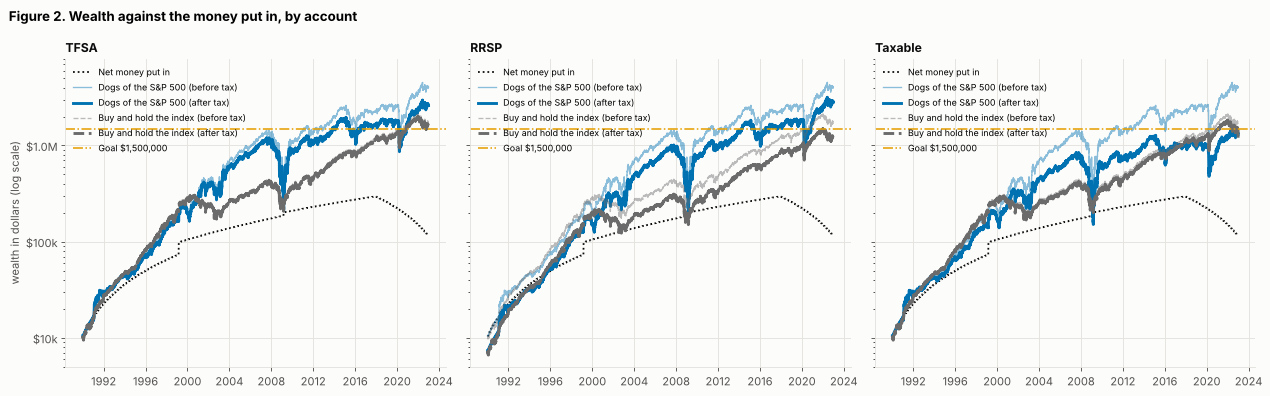

Table 2. Final wealth by account (the index is the base case in every account)


In [6]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, a in zip(axs, ACCOUNTS):
    s = S[a]
    tp._ax(ax)
    ax.plot(s.index, s["contributed"].clip(lower=1), color=tp.INK, lw=1.6, ls=":", label="Net money put in")
    ax.plot(s.index, s["strategy_pre"], color=tp.PALETTE[0], lw=1.2, alpha=0.45, label=f"{DOGS_LABEL} (before tax)")
    ax.plot(s.index, s["strategy_after_tax"], color=tp.PALETTE[0], lw=2.6, label=f"{DOGS_LABEL} (after tax)")
    ax.plot(s.index, s["index_pre"], color=tp.INDEX_COL, lw=1.2, alpha=0.45, ls="--", label=f"{INDEX_LABEL} (before tax)")
    ax.plot(s.index, s["index_after_tax"], color=tp.INDEX_COL, lw=2.6, ls="--", label=f"{INDEX_LABEL} (after tax)")
    ax.axhline(GOAL, color=tp.AMBER, lw=1.4, ls="-.", label=f"Goal {usd(GOAL).replace(chr(92), '')}")
    ax.set_yscale("log")
    ax.set_ylim(5_000, 8_000_000)
    ax.yaxis.set_major_formatter(lambda v, _: f"${v / 1e6:.1f}M" if v >= 1e6 else f"${v / 1e3:.0f}k")
    ax.set_title(f"{NAME[a]}", loc="left", fontsize=11, fontweight="bold", color=tp.INK)
    ax.legend(fontsize=8, loc="upper left", frameon=False)
axs[0].set_ylabel("wealth in dollars (log scale)")
fig.suptitle("Figure 2. Wealth against the money put in, by account", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); show(fig)

rows = []
for a in ACCOUNTS:
    for who, nm in (("strategy", DOGS_LABEL), ("index", INDEX_LABEL)):
        rows.append({"Account": NAME[a], "Holding": nm, "Net money in": m(a, who, "Contributed"), "Final, before tax": m(a, who, "FinalPreTax"),
                     "Final, after tax": m(a, who, "FinalAfterTax"), "Tax paid": m(a, who, "TaxPaid"),
                     "After tax, in 1990 dollars": m(a, who, "FinalAfterTaxReal"), "After tax, multiple of money in": m(a, who, "FinalAfterTax") / m(a, who, "Contributed")})
tab2 = pd.DataFrame(rows).set_index(["Account", "Holding"])
print("Table 2. Final wealth by account (the index is the base case in every account)")
tab2.style.format({c: "${:,.0f}" for c in tab2.columns[:-1]} | {tab2.columns[-1]: "{:.1f}x"})

In [7]:
assert S["taxable"]["strategy_after_tax"].min() > 0 and all(S[a][f"{w}_after_tax"].min() > 0 for a in ACCOUNTS for w in ("strategy", "index"))
best_acct = {w: max(ACCOUNTS, key=lambda a: m(a, w, "FinalAfterTax")) for w in ("strategy", "index")}
worst_acct = {w: min(ACCOUNTS, key=lambda a: m(a, w, "FinalAfterTax")) for w in ("strategy", "index")}
lead = {a: m(a, "difference", "FinalAfterTax") for a in ACCOUNTS}
say(f'''
### What the evidence says

Before tax the dogs turned {usd(NET)} of net money into {usd(m("tfsa", "strategy", "FinalPreTax"))}, {mult(m("tfsa", "strategy", "FinalPreTax"), NET)} times what was put in, and the index into {usd(m("tfsa", "index", "FinalPreTax"))}, {mult(m("tfsa", "index", "FinalPreTax"), NET)} times. After tax the dogs were ahead of the index in every account: by {usd(lead["tfsa"])} in the TFSA, {usd(lead["rrsp"])} in the RRSP and {usd(lead["taxable"])} in the taxable account. The account mattered more than anything else the plan controls. The same dogs ended {usd(m(best_acct["strategy"], "strategy", "FinalAfterTax") - m(worst_acct["strategy"], "strategy", "FinalAfterTax"))} higher in the {NAME[best_acct["strategy"]]} than in the {NAME[worst_acct["strategy"]]}, and the index {usd(m(best_acct["index"], "index", "FinalAfterTax") - m(worst_acct["index"], "index", "FinalAfterTax"))} higher in the {NAME[best_acct["index"]]} than in the {NAME[worst_acct["index"]]}. The dogs pay more tax than the index everywhere ({usd(m("taxable", "strategy", "TaxPaid"))} against {usd(m("taxable", "index", "TaxPaid"))} in the taxable account) because they turn over most of the portfolio every year and hold high payers, yet their lead before tax is large enough to survive it. Wealth at the end is also the end of a path that included an {pc(-m("tfsa", "strategy", "MaxDD"))} fall for the dogs, which Section 3 measures. Because the tax is paid from the portfolio, the after-tax line is the wealth the investor would have held and stays above zero even through the March 2009 low.
''')
assert all(v > 0 for v in lead.values()) and worst_acct["strategy"] == "taxable"
assert all(m(a, "strategy", "TaxPaid") > m(a, "index", "TaxPaid") for a in ACCOUNTS)


### What the evidence says

Before tax the dogs turned \$115,904 of net money into \$4,036,691, 34.8 times what was put in, and the index into \$1,674,844, 14.5 times. After tax the dogs were ahead of the index in every account: by \$1,053,552 in the TFSA, \$1,653,344 in the RRSP and \$90,280 in the taxable account. The account mattered more than anything else the plan controls. The same dogs ended \$1,531,457 higher in the RRSP than in the Taxable, and the index \$385,624 higher in the TFSA than in the RRSP. The dogs pay more tax than the index everywhere (\$698,597 against \$327,447 in the taxable account) because they turn over most of the portfolio every year and hold high payers, yet their lead before tax is large enough to survive it. Wealth at the end is also the end of a path that included an 83.37% fall for the dogs, which Section 3 measures. Because the tax is paid from the portfolio, the after-tax line is the wealth the investor would have held and stays above zero even through the March 2009 low.


## 3. The metrics: money-weighted, time-weighted, alpha, beta, Sharpe, and the three ways to count tax and inflation

What does "the strategy returned x% a year" mean when money moves in and out? The plan reports two answers and they are different questions. The **XIRR** (money-weighted return) is the single yearly rate that, applied to every dated flow, makes the contributions grow to the final value and the withdrawals match; it is what the investor's own dollars earned, so it depends on when the money was there to earn it. The **TWR** (time-weighted return) strips the flows out: it is the yearly growth of one dollar left in the strategy for the whole window, the record of the strategy itself, and it is the series the risk measures below are computed on. When the money goes in late, as here, the XIRR leans on the later years; when a manager's skill is the question, the TWR is the fairer number. Alpha, beta and Sharpe come from monthly time-weighted returns: beta and alpha are the slope and intercept of the strategy's monthly excess return (over the US 10-year yield, a stand-in) on the index's, alpha annualised, and Sharpe is the mean excess return over its standard deviation, times the square root of 12.

Table 3 shows the TFSA case in full, strategy against index with the difference, which is the plan's three-row result. Table 4 gives the money-weighted return counted four ways in each account: before tax, after tax, after inflation (every flow deflated by CPI to 1990 dollars), and after both. Figure 3 draws the TFSA's XIRR and TWR, strategy against the base case.

In [8]:
cols = ["Contributed", "FinalPreTax", "FinalAfterTax", "FinalAfterTaxReal", "XIRR", "XIRRAfterTax", "XIRRAfterTaxReal", "TWR", "Alpha", "Beta", "Sharpe", "Vol", "MaxDD", "TaxPaid"]
t3 = plans["tfsa"].metrics[cols].copy()
t3.index = [DOGS_LABEL, INDEX_LABEL, "Difference"]
print("Table 3. The plan's metrics in the TFSA (three rows: strategy, the base case, the difference)")
money_c = ["Contributed", "FinalPreTax", "FinalAfterTax", "FinalAfterTaxReal", "TaxPaid"]
pct_c = ["XIRR", "XIRRAfterTax", "XIRRAfterTaxReal", "TWR", "Alpha", "Vol", "MaxDD"]
display(t3.style.format({c: "${:,.0f}" for c in money_c} | {c: "{:.2%}" for c in pct_c} | {"Beta": "{:.2f}", "Sharpe": "{:.2f}"}, na_rep="-"))

def xi(a, who):
    return [m(a, who, c) for c in ("XIRR", "XIRRAfterTax", "XIRRReal", "XIRRAfterTaxReal")]
rows = []
for a in ACCOUNTS:
    for who, nm in (("strategy", DOGS_LABEL), ("index", INDEX_LABEL), ("difference", "Difference")):
        rows.append([NAME[a], nm, *xi(a, who)])
tab4 = pd.DataFrame(rows, columns=["Account", "Holding", "Before tax", "After tax", "After inflation", "After tax and inflation"]).set_index(["Account", "Holding"])
print("Table 4. Money-weighted return (XIRR) counted four ways, by account")
tab4.style.format("{:.2%}")

Table 3. The plan's metrics in the TFSA (three rows: strategy, the base case, the difference)


,Contributed,FinalPreTax,FinalAfterTax,FinalAfterTaxReal,XIRR,XIRRAfterTax,XIRRAfterTaxReal,TWR,Alpha,Beta,Sharpe,Vol,MaxDD,TaxPaid
Dogs of the S&P 500,"$115,904","$4,036,691","$2,611,567","$1,121,014",12.84%,11.02%,8.34%,13.23%,4.97%,1.06,0.46,25.10%,-83.37%,"$420,968"
Buy and hold the index,"$115,904","$1,674,844","$1,558,015","$668,777",9.18%,8.89%,6.27%,9.54%,0.00%,1.00,0.41,15.00%,-55.28%,"$45,491"
Difference,$0,"$2,361,846","$1,053,552","$452,237",3.66%,2.13%,2.07%,3.69%,4.97%,0.06,0.05,10.11%,-28.09%,"$375,477"


Table 4. Money-weighted return (XIRR) counted four ways, by account


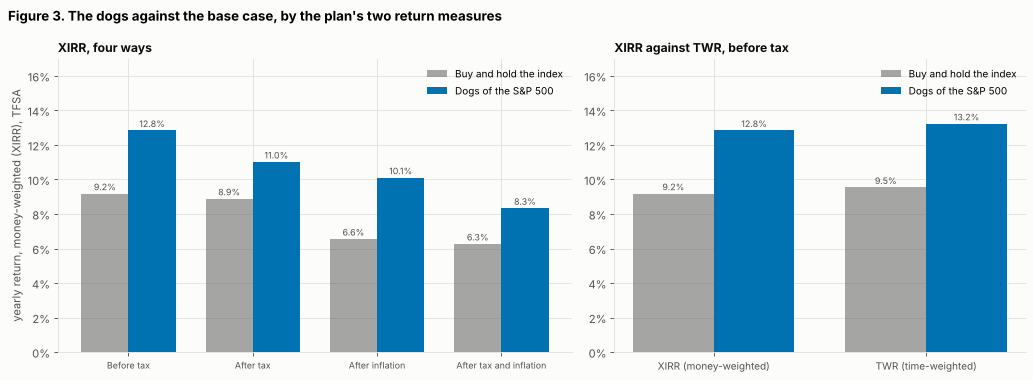

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
tp._ax(axs[0]); tp._ax(axs[1])
labels = ["Before tax", "After tax", "After inflation", "After tax and inflation"]
x = np.arange(4); w = 0.38
axs[0].bar(x - w / 2, xi("tfsa", "index"), w, color=tp.INDEX_COL, alpha=0.6, label=INDEX_LABEL)
axs[0].bar(x + w / 2, xi("tfsa", "strategy"), w, color=tp.PALETTE[0], label=DOGS_LABEL)
for i, (a_, b_) in enumerate(zip(xi("tfsa", "index"), xi("tfsa", "strategy"))):
    axs[0].text(i - w / 2, a_ + 0.002, f"{100 * a_:.1f}%", ha="center", fontsize=8, color=tp.INK2)
    axs[0].text(i + w / 2, b_ + 0.002, f"{100 * b_:.1f}%", ha="center", fontsize=8, color=tp.INK2)
axs[0].set_xticks(x, labels, fontsize=8); axs[0].yaxis.set_major_formatter(lambda v, _: f"{100 * v:.0f}%")
axs[0].set_ylabel("yearly return, money-weighted (XIRR), TFSA")
axs[0].set_ylim(0, 0.17)
axs[0].legend(fontsize=9, loc="upper right", frameon=False)
axs[0].set_title("XIRR, four ways", loc="left", fontsize=11, fontweight="bold", color=tp.INK)
y = np.arange(2)
axs[1].bar(y - w / 2, [m("tfsa", "index", "XIRR"), m("tfsa", "index", "TWR")], w, color=tp.INDEX_COL, alpha=0.6, label=INDEX_LABEL)
axs[1].bar(y + w / 2, [m("tfsa", "strategy", "XIRR"), m("tfsa", "strategy", "TWR")], w, color=tp.PALETTE[0], label=DOGS_LABEL)
axs[1].set_xticks(y, ["XIRR (money-weighted)", "TWR (time-weighted)"], fontsize=9)
for i, (a_, b_) in enumerate(zip([m("tfsa", "index", "XIRR"), m("tfsa", "index", "TWR")], [m("tfsa", "strategy", "XIRR"), m("tfsa", "strategy", "TWR")])):
    axs[1].text(i - w / 2, a_ + 0.002, f"{100 * a_:.1f}%", ha="center", fontsize=8, color=tp.INK2)
    axs[1].text(i + w / 2, b_ + 0.002, f"{100 * b_:.1f}%", ha="center", fontsize=8, color=tp.INK2)
axs[1].set_ylim(0, 0.17)
axs[1].yaxis.set_major_formatter(lambda v, _: f"{100 * v:.0f}%")
axs[1].legend(fontsize=9, loc="upper right", frameon=False)
axs[1].set_title("XIRR against TWR, before tax", loc="left", fontsize=11, fontweight="bold", color=tp.INK)
fig.suptitle("Figure 3. The dogs against the base case, by the plan's two return measures", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); show(fig)

In [10]:
gap_x = m("tfsa", "strategy", "XIRR") - m("tfsa", "strategy", "TWR")
assert gap_x < 0
say(f'''
### What the evidence says

The two returns tell nearly the same story here. The dogs earned {pc(m("tfsa", "strategy", "XIRR"))} a year on the investor's own dollars (XIRR) and {pc(m("tfsa", "strategy", "TWR"))} for a dollar left alone (TWR), the XIRR sitting {pts(-gap_x)} points below the TWR; the index earned {pc(m("tfsa", "index", "XIRR"))} and {pc(m("tfsa", "index", "TWR"))}. The dogs lead by {pts(m("tfsa", "difference", "XIRR"))} points a year on the money-weighted measure and {pts(m("tfsa", "difference", "TWR"))} on the time-weighted one, so the schedule of flows did not manufacture the lead. Counted four ways, the dogs' XIRR in the TFSA falls from {pc(m("tfsa", "strategy", "XIRR"))} before tax to {pc(m("tfsa", "strategy", "XIRRAfterTax"))} after tax (the 15% US withholding on dividends), to {pc(m("tfsa", "strategy", "XIRRReal"))} after inflation and to {pc(m("tfsa", "strategy", "XIRRAfterTaxReal"))} after both; in the taxable account the after-tax figure is {pc(m("taxable", "strategy", "XIRRAfterTax"))} and in the RRSP {pc(m("rrsp", "strategy", "XIRRAfterTax"))}, against {pc(m("taxable", "index", "XIRRAfterTax"))} and {pc(m("rrsp", "index", "XIRRAfterTax"))} for the index.

The risk side is where the dogs pay. Their beta is {m("tfsa", "strategy", "Beta"):.2f}, so the market explains most of their moves; their alpha is {pc(m("tfsa", "strategy", "Alpha"))} a year; their Sharpe ratio is {m("tfsa", "strategy", "Sharpe"):.2f} against {m("tfsa", "index", "Sharpe"):.2f} for the index, a small edge; they are {pc(m("tfsa", "strategy", "Vol"))} volatile against {pc(m("tfsa", "index", "Vol"))}, fell {pc(-m("tfsa", "strategy", "MaxDD"))} at the worst against {pc(-m("tfsa", "index", "MaxDD"))}, and have a tracking error of {pc(m("tfsa", "strategy", "TrackingError"))} and an information ratio of {m("tfsa", "strategy", "InfoRatio"):.2f}. A lead of {pts(m("tfsa", "difference", "TWR"))} points a year with an information ratio of that size is the kind that one history can produce by luck, which Section 6 puts a number on.
''')
assert m("tfsa", "difference", "XIRR") > 0 and m("tfsa", "difference", "TWR") > 0 and m("tfsa", "strategy", "Sharpe") > m("tfsa", "index", "Sharpe")
assert m("tfsa", "strategy", "XIRR") > m("tfsa", "strategy", "XIRRAfterTax") > m("tfsa", "strategy", "XIRRAfterTaxReal") and m("tfsa", "strategy", "Vol") > m("tfsa", "index", "Vol")


### What the evidence says

The two returns tell nearly the same story here. The dogs earned 12.84% a year on the investor's own dollars (XIRR) and 13.23% for a dollar left alone (TWR), the XIRR sitting 0.39 points below the TWR; the index earned 9.18% and 9.54%. The dogs lead by 3.66 points a year on the money-weighted measure and 3.69 on the time-weighted one, so the schedule of flows did not manufacture the lead. Counted four ways, the dogs' XIRR in the TFSA falls from 12.84% before tax to 11.02% after tax (the 15% US withholding on dividends), to 10.11% after inflation and to 8.34% after both; in the taxable account the after-tax figure is 8.13% and in the RRSP 11.24%, against 7.84% and 7.51% for the index.

The risk side is where the dogs pay. Their beta is 1.06, so the market explains most of their moves; their alpha is 4.97% a year; their Sharpe ratio is 0.46 against 0.41 for the index, a small edge; they are 25.10% volatile against 15.00%, fell 83.37% at the worst against 55.28%, and have a tracking error of 19.39% and an information ratio of 0.28. A lead of 3.69 points a year with an information ratio of that size is the kind that one history can produce by luck, which Section 6 puts a number on.


## 4. Invest on arrival, or hold the cash until the next rebalance

A contribution arrives between rebalances. The question is what it is worth to put it to work on the next trading day, as the plan does by default (`cash_timing="invest"`), compared with leaving it in cash until the dogs are next renewed (`cash_timing="hold"`), which is what a portfolio that only trades on its rebalance dates would do. The cash earns the library's cash rate, which is zero in this lab, so the hold run measures the cost of waiting. The dogs rebalance once a year, so a contribution can wait up to eleven months, and the index, which is always invested, is unaffected: it is the base case in both runs.

Figure 4 shows, for the TFSA, the dogs' after-tax wealth when invested on arrival and when held in cash, against the index (left), and the cash balance the hold run carries (right).

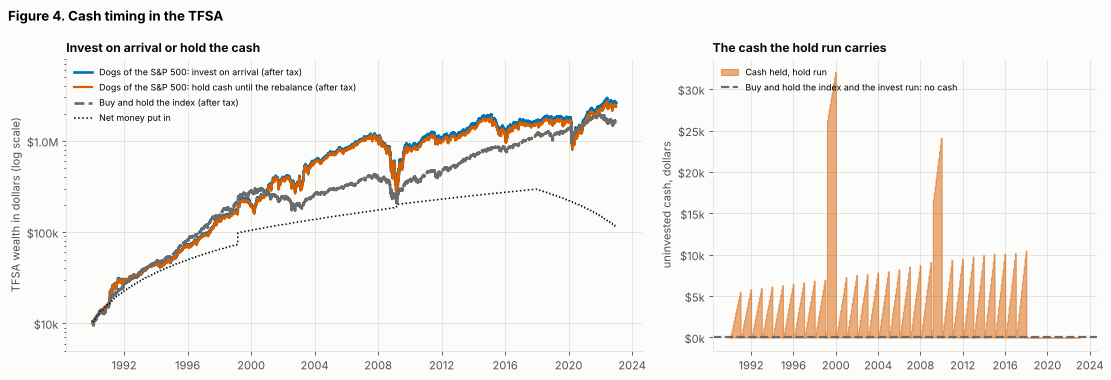

Table 5. Cash timing in the TFSA (the index is the base case in both)


,"Final, after tax","XIRR, after tax","TWR, after tax",Sharpe
Dogs of the S&P 500: invest on arrival,"$2,611,567",11.02%,11.51%,0.46
Dogs of the S&P 500: hold cash,"$2,393,803",10.66%,11.14%,0.45
Buy and hold the index,"$1,558,015",8.89%,9.23%,0.41


In [11]:
H = hold.series
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
tp._ax(axs[0]); tp._ax(axs[1])
axs[0].plot(S["tfsa"].index, S["tfsa"]["strategy_after_tax"], color=tp.PALETTE[0], lw=2.4, label=f"{DOGS_LABEL}: invest on arrival (after tax)")
axs[0].plot(H.index, H["strategy_after_tax"], color=tp.PALETTE[1], lw=2.0, label=f"{DOGS_LABEL}: hold cash until the rebalance (after tax)")
axs[0].plot(S["tfsa"].index, S["tfsa"]["index_after_tax"], color=tp.INDEX_COL, lw=2.4, ls="--", label=f"{INDEX_LABEL} (after tax)")
axs[0].plot(S["tfsa"].index, S["tfsa"]["contributed"].clip(lower=1), color=tp.INK, lw=1.4, ls=":", label="Net money put in")
axs[0].set_yscale("log"); axs[0].set_ylim(5_000, 8_000_000)
axs[0].yaxis.set_major_formatter(lambda v, _: f"${v / 1e6:.1f}M" if v >= 1e6 else f"${v / 1e3:.0f}k")
axs[0].set_ylabel("TFSA wealth in dollars (log scale)")
axs[0].legend(fontsize=8, loc="upper left", frameon=False)
axs[0].set_title("Invest on arrival or hold the cash", loc="left", fontsize=11, fontweight="bold", color=tp.INK)
axs[1].fill_between(H.index, H["cash"], color=tp.PALETTE[1], alpha=0.5, label="Cash held, hold run")
axs[1].axhline(0, color=tp.INDEX_COL, lw=2, ls="--", label=f"{INDEX_LABEL} and the invest run: no cash")
axs[1].yaxis.set_major_formatter(lambda v, _: f"${v / 1e3:.0f}k")
axs[1].set_ylabel("uninvested cash, dollars")
axs[1].legend(fontsize=8, loc="upper left", frameon=False)
axs[1].set_title("The cash the hold run carries", loc="left", fontsize=11, fontweight="bold", color=tp.INK)
fig.suptitle("Figure 4. Cash timing in the TFSA", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); show(fig)

hm = hold.metrics
t5 = pd.DataFrame({"Final, after tax": [m("tfsa", "strategy", "FinalAfterTax"), hm.loc["strategy", "FinalAfterTax"], m("tfsa", "index", "FinalAfterTax")],
                   "XIRR, after tax": [m("tfsa", "strategy", "XIRRAfterTax"), hm.loc["strategy", "XIRRAfterTax"], m("tfsa", "index", "XIRRAfterTax")],
                   "TWR, after tax": [m("tfsa", "strategy", "TWRAfterTax"), hm.loc["strategy", "TWRAfterTax"], m("tfsa", "index", "TWRAfterTax")],
                   "Sharpe": [m("tfsa", "strategy", "Sharpe"), hm.loc["strategy", "Sharpe"], m("tfsa", "index", "Sharpe")]},
                  index=[f"{DOGS_LABEL}: invest on arrival", f"{DOGS_LABEL}: hold cash", INDEX_LABEL])
print("Table 5. Cash timing in the TFSA (the index is the base case in both)")
t5.style.format({"Final, after tax": "${:,.0f}", "XIRR, after tax": "{:.2%}", "TWR, after tax": "{:.2%}", "Sharpe": "{:.2f}"})

In [12]:
CASH_AVG, CASH_MAX = float(H["cash"].mean()), float(H["cash"].max())
cost_x = m("tfsa", "strategy", "XIRRAfterTax") - hm.loc["strategy", "XIRRAfterTax"]
say(f'''
### What the evidence says

Waiting cost money. Investing each contribution on arrival ended at {usd(m("tfsa", "strategy", "FinalAfterTax"))} after tax in the TFSA and holding it in cash until the next rebalance at {usd(hm.loc["strategy", "FinalAfterTax"])}, a difference of {usd(cost_hold)} ({pc(cost_hold / m("tfsa", "strategy", "FinalAfterTax"))} of the final wealth), or {pts(cost_x)} points of money-weighted return a year. The hold run carried {usd(CASH_AVG)} of cash on average and {usd(CASH_MAX)} at most, idle in a market that rose most years. The cost of waiting is a cost of this history, in which stocks rose; in a decade that fell, holding cash until a rebalance would have helped. The default of investing on arrival is the better description of a monthly saver, and the hold run is the right model for a portfolio that only trades on its rebalance dates. Either way the dogs finished ahead of the base case ({usd(hm.loc["difference", "FinalAfterTax"])} after tax with the cash held), so the conclusion about the strategy does not depend on the choice.
''')
assert cost_hold > 0 and hm.loc["difference", "FinalAfterTax"] > 0 and H["cash"].max() > 0 and S["tfsa"]["cash"].max() == 0


### What the evidence says

Waiting cost money. Investing each contribution on arrival ended at \$2,611,567 after tax in the TFSA and holding it in cash until the next rebalance at \$2,393,803, a difference of \$217,764 (8.34% of the final wealth), or 0.36 points of money-weighted return a year. The hold run carried \$4,449 of cash on average and \$32,093 at most, idle in a market that rose most years. The cost of waiting is a cost of this history, in which stocks rose; in a decade that fell, holding cash until a rebalance would have helped. The default of investing on arrival is the better description of a monthly saver, and the hold run is the right model for a portfolio that only trades on its rebalance dates. Either way the dogs finished ahead of the base case (\$835,788 after tax with the cash held), so the conclusion about the strategy does not depend on the choice.


## 5. The goal: when did the plan first hold \$1.5 million, after tax?

A plan usually has a number it is meant to reach. The question here is when each side first held a nominal \$1,500,000 after tax, and how far from it the plan finished, given that the plan then took \$3,000 a month out. The plan reports `YearsToGoal` (years from the start until the after-tax wealth first reaches the goal) and `GoalShortfall` (the gap at the end, zero when the goal is met). Figure 5 draws the after-tax wealth of the dogs and of the index in each account against the goal, with a marker on the day each first crosses it.

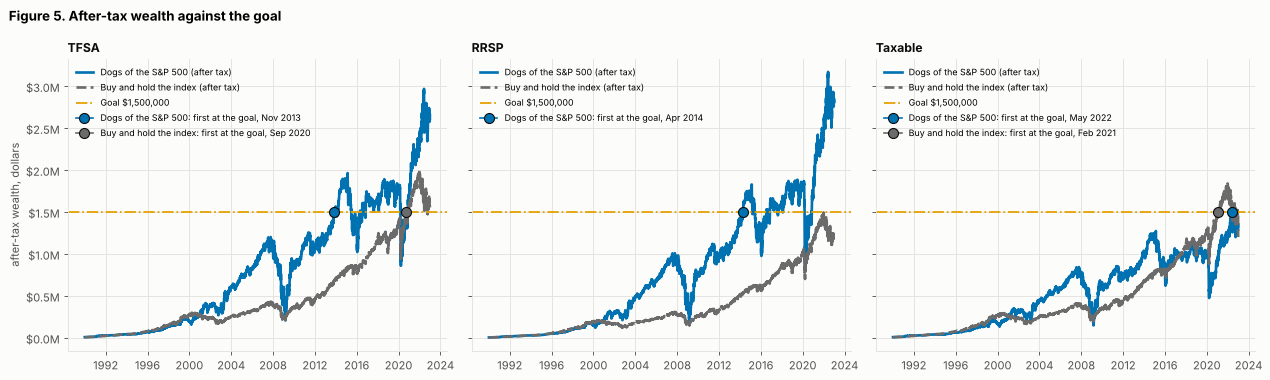

Table 6. The $1.5 million goal, after tax (the index is the base case)


In [13]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, a in zip(axs, ACCOUNTS):
    tp._ax(ax)
    s = S[a]
    ax.plot(s.index, s["strategy_after_tax"], color=tp.PALETTE[0], lw=2.4, label=f"{DOGS_LABEL} (after tax)")
    ax.plot(s.index, s["index_after_tax"], color=tp.INDEX_COL, lw=2.4, ls="--", label=f"{INDEX_LABEL} (after tax)")
    ax.axhline(GOAL, color=tp.AMBER, lw=1.6, ls="-.", label=f"Goal {usd(GOAL).replace(chr(92), '')}")
    for who, col in (("strategy", tp.PALETTE[0]), ("index", tp.INDEX_COL)):
        d = reached[a, who]
        if d is not None:
            ax.plot([d], [GOAL], marker="o", ms=9, color=col, mec=tp.INK, zorder=5,
                    label=f"{DOGS_LABEL if who == 'strategy' else INDEX_LABEL}: first at the goal, {d:%b %Y}")
    ax.yaxis.set_major_formatter(lambda v, _: f"${v / 1e6:.1f}M")
    ax.set_title(NAME[a], loc="left", fontsize=11, fontweight="bold", color=tp.INK)
    ax.legend(fontsize=8, loc="upper left", frameon=False)
axs[0].set_ylabel("after-tax wealth, dollars")
fig.suptitle("Figure 5. After-tax wealth against the goal", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); show(fig)

rows = []
for a in ACCOUNTS:
    for who, nm in (("strategy", DOGS_LABEL), ("index", INDEX_LABEL)):
        d = reached[a, who]
        rows.append({"Account": NAME[a], "Holding": nm, "First at the goal": "never" if d is None else f"{d:%b %Y}",
                     "Years to the goal": m(a, who, "YearsToGoal"), "Final, after tax": m(a, who, "FinalAfterTax"),
                     "Short of the goal at the end": m(a, who, "GoalShortfall")})
tab6 = pd.DataFrame(rows).set_index(["Account", "Holding"])
print("Table 6. The $1.5 million goal, after tax (the index is the base case)")
tab6.style.format({"Years to the goal": "{:.1f}", "Final, after tax": "${:,.0f}", "Short of the goal at the end": "${:,.0f}"}, na_rep="never")

In [14]:
late = [a for a in ACCOUNTS if m(a, "index", "GoalShortfall") > 0]
assert reached["rrsp", "index"] is None and reached["taxable", "index"] is not None
say(f'''
### What the evidence says

The dogs first held {usd(GOAL)} after tax {yrs_goal["tfsa", "strategy"]:.1f} years in the TFSA ({reached["tfsa", "strategy"]:%B %Y}) and {yrs_goal["rrsp", "strategy"]:.1f} years in the RRSP ({reached["rrsp", "strategy"]:%B %Y}); the line dips back below the goal in later falls and finishes above it in both, by {usd(m("tfsa", "strategy", "FinalAfterTax") - GOAL)} in the TFSA and {usd(m("rrsp", "strategy", "FinalAfterTax") - GOAL)} in the RRSP. In the taxable account, where each year's tax comes out of the portfolio and stops compounding, they reached it only in {reached["taxable", "strategy"]:%B %Y}, {yrs_goal["taxable", "strategy"]:.1f} years in, and finished {usd(m("taxable", "strategy", "GoalShortfall"))} short of it. The index took {yrs_goal["tfsa", "index"]:.1f} years in the TFSA, {yrs_goal["tfsa", "index"] - yrs_goal["tfsa", "strategy"]:.1f} years longer than the dogs, and finished above the goal there; in the taxable account it reached the goal in {reached["taxable", "index"]:%B %Y} ({yrs_goal["taxable", "index"]:.1f} years), before the dogs, then fell back and finished {usd(m("taxable", "index", "GoalShortfall"))} short. In the RRSP, with 30% of the balance owed on withdrawal, the index never held {usd(GOAL)} after tax and finished {usd(m("rrsp", "index", "GoalShortfall"))} short. On this history the goal is therefore met at the end by the dogs in the TFSA and the RRSP and by the index only in the TFSA. The margin is not small ({usd(min(m(a, "strategy", "FinalAfterTax") for a in ("tfsa", "rrsp")) - GOAL)} above the goal for the dogs in the {NAME[min(("tfsa", "rrsp"), key=lambda a: m(a, "strategy", "FinalAfterTax"))]}, the account that leaves the least of the two), but it comes from one path, and the plan\'s withdrawals of \\$3,000 a month begin only in 2018, after the dogs had already crossed the line in the TFSA and the RRSP. Section 6 asks how often a different order of the same returns would have missed it.
''')
assert m("tfsa", "strategy", "GoalShortfall") == 0 and m("rrsp", "strategy", "GoalShortfall") == 0 and m("taxable", "strategy", "GoalShortfall") > 0
assert m("tfsa", "index", "GoalShortfall") == 0 and len(late) == 2 and reached["taxable", "index"] < reached["taxable", "strategy"]
assert all(reached[a, "strategy"].year in (2013, 2014) for a in ("tfsa", "rrsp"))


### What the evidence says

The dogs first held \$1,500,000 after tax 23.9 years in the TFSA (November 2013) and 24.3 years in the RRSP (April 2014); the line dips back below the goal in later falls and finishes above it in both, by \$1,111,567 in the TFSA and \$1,325,735 in the RRSP. In the taxable account, where each year's tax comes out of the portfolio and stops compounding, they reached it only in May 2022, 32.4 years in, and finished \$205,722 short of it. The index took 30.7 years in the TFSA, 6.8 years longer than the dogs, and finished above the goal there; in the taxable account it reached the goal in February 2021 (31.1 years), before the dogs, then fell back and finished \$296,002 short. In the RRSP, with 30% of the balance owed on withdrawal, the index never held \$1,500,000 after tax and finished \$327,609 short. On this history the goal is therefore met at the end by the dogs in the TFSA and the RRSP and by the index only in the TFSA. The margin is not small (\$1,111,567 above the goal for the dogs in the TFSA, the account that leaves the least of the two), but it comes from one path, and the plan's withdrawals of \$3,000 a month begin only in 2018, after the dogs had already crossed the line in the TFSA and the RRSP. Section 6 asks how often a different order of the same returns would have missed it.


## 6. Monte Carlo: how much of this was the order of the returns?

The straight calculation is one path. The question is how the plan would have fared on other orders of the same months, and in particular how often the dogs would have finished ahead of the index after tax, how often each side would have missed the \$1.5 million goal, and what the worst twelve months did when they came early or late. The study resamples the plan's own monthly history (the strategy, the index, the risk-free rate and inflation together, in 12-month blocks, so a bad year for one is a bad year for the other) into 500 paths of the same 33 years, replays the same dated flows on every path, and pays on each path, every year, the share of the portfolio that the straight run paid in tax that year (in the TFSA, the withholding), and at the end the RRSP balance tax or the tax on the liquidated gain. That is an approximation, not a re-simulation; Section 7 says what it leaves out.

Figure 6 is the fan of after-tax wealth, TFSA on the left and taxable account on the right: the median of the dogs and of the index with their 25-75% and 5-95% bands, the net money put in, and the goal. Figure 7 shows the terminal wealth of the two sides and, path by path, the difference. Figure 8 groups the paths by where their worst twelve months fell, in the first, middle or last third of the plan.

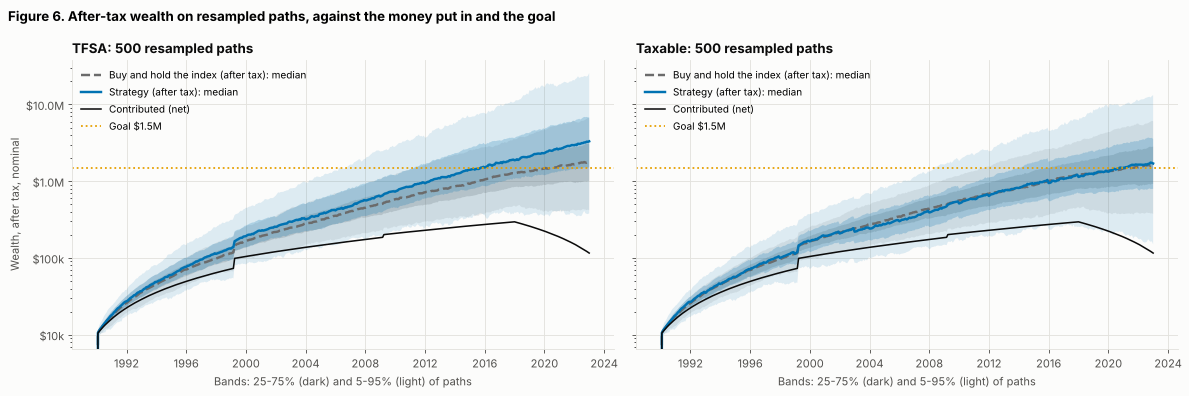

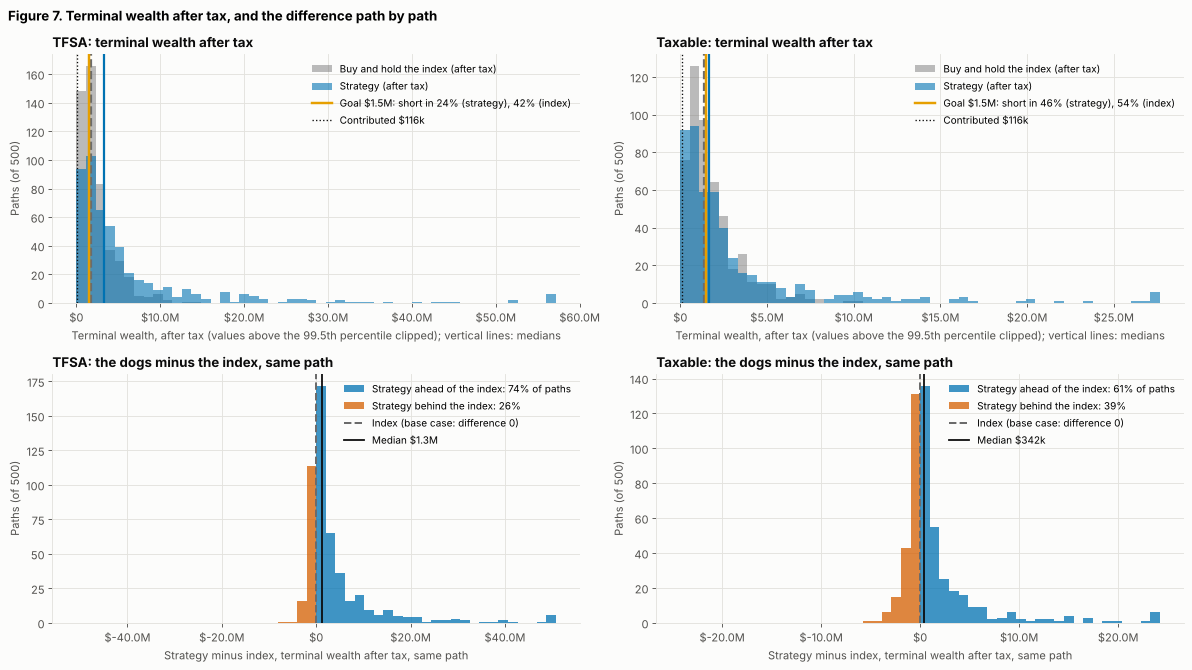

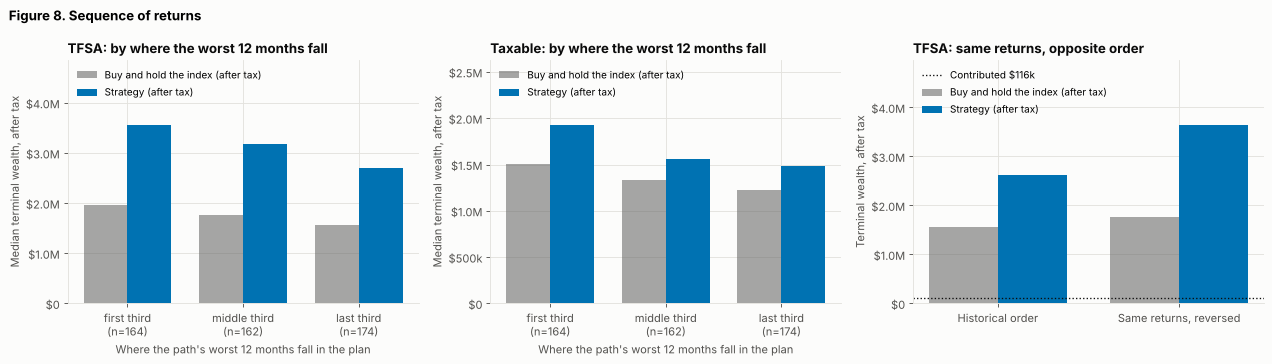

Table 7. Terminal wealth after tax on 500 resampled paths (the index is the base case)


In [15]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, a in zip(axs, ("tfsa", "taxable")):
    pp.fan_chart(mcs[a], ax=ax, legend=True, log=True, title=f"{NAME[a]}: {N_PATHS} resampled paths")
axs[1].set_ylabel("")
fig.suptitle("Figure 6. After-tax wealth on resampled paths, against the money put in and the goal", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); show(fig)

fig, axs = plt.subplots(2, 2, figsize=(15, 8.5))
for j, a in enumerate(("tfsa", "taxable")):
    pp.terminal_hist(mcs[a], ax=axs[0, j], legend=True, title=f"{NAME[a]}: terminal wealth after tax")
    pp.paired_hist(mcs[a], ax=axs[1, j], legend=True, title=f"{NAME[a]}: the dogs minus the index, same path")
fig.suptitle("Figure 7. Terminal wealth after tax, and the difference path by path", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); show(fig)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
pp.sequence_bars(mcs["tfsa"], ax=axs[0], legend=True, title="TFSA: by where the worst 12 months fall")
pp.sequence_bars(mcs["taxable"], ax=axs[1], legend=True, title="Taxable: by where the worst 12 months fall")
pp.reversal_bars(mcs["tfsa"], ax=axs[2], legend=True, title="TFSA: same returns, opposite order")
for ax_ in axs:
    ax_.set_ylim(0, ax_.get_ylim()[1] * 1.3)
fig.suptitle("Figure 8. Sequence of returns", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); show(fig)

rows = []
for a in ("tfsa", "taxable"):
    q = mcs[a].quantiles
    for who, nm in (("strategy", DOGS_LABEL), ("index", INDEX_LABEL)):
        rows.append({"Account": NAME[a], "Holding": nm, **{f"{p}th percentile": q.loc[p, f"{who}_after_tax"] for p in (5, 25, 50, 75, 95)},
                     "Ahead of the index": mcs[a].p_beat_index if who == "strategy" else np.nan,
                     "Short of the goal": mcs[a].p_shortfall if who == "strategy" else mcs[a].p_shortfall_index})
tab7 = pd.DataFrame(rows).set_index(["Account", "Holding"])
print("Table 7. Terminal wealth after tax on", N_PATHS, "resampled paths (the index is the base case)")
tab7.style.format({c: "${:,.0f}" for c in tab7.columns[:5]} | {"Ahead of the index": "{:.0%}", "Short of the goal": "{:.0%}"}, na_rep="")

In [16]:
sq = {a: mcs[a].sequence for a in ("tfsa", "taxable")}
rv = mcs["tfsa"].reversal
say(f'''
### What the evidence says

On {N_PATHS} resampled paths the dogs finished ahead of the index after tax on {pc(mt.p_beat_index)} of paths in the TFSA and {pc(mx.p_beat_index)} in the taxable account: a lead that is more likely than not, but nowhere near certain, and smaller where tax bites. The median after-tax final wealth was {usd(mt.quantiles.loc[50, "strategy_after_tax"])} for the dogs against {usd(mt.quantiles.loc[50, "index_after_tax"])} for the index in the TFSA, and {usd(mx.quantiles.loc[50, "strategy_after_tax"])} against {usd(mx.quantiles.loc[50, "index_after_tax"])} in the taxable account. The spread is wide: the dogs' 5th percentile in the TFSA was {usd(mt.quantiles.loc[5, "strategy_after_tax"])} and their 95th {usd(mt.quantiles.loc[95, "strategy_after_tax"])}, against {usd(mt.quantiles.loc[5, "index_after_tax"])} and {usd(mt.quantiles.loc[95, "index_after_tax"])} for the index, so the strategy buys a fatter right tail and a similar left tail. The goal tells the same story: {pc(mt.p_shortfall)} of the dogs' paths and {pc(mt.p_shortfall_index)} of the index's finished below {usd(GOAL)} in the TFSA, {pc(mx.p_shortfall)} and {pc(mx.p_shortfall_index)} in the taxable account. The history replayed through the Monte Carlo reproduces the straight run: {usd(MC_FWD)} for the dogs in the TFSA, the {100 * HIST_PCT:.0f}th percentile of their resampled terminal wealth, and the same to the dollar for the index and for the other accounts.

The order of the returns matters through the withdrawals. When the worst twelve months fell in the first third of the plan, the dogs' median TFSA outcome was {usd(sq["tfsa"].loc["first", "strategy_median"])}, in the middle third {usd(sq["tfsa"].loc["middle", "strategy_median"])} and in the last third {usd(sq["tfsa"].loc["last", "strategy_median"])}, and the share of paths below the goal was {pc(sq["tfsa"].loc["first", "p_shortfall"])}, {pc(sq["tfsa"].loc["middle", "p_shortfall"])} and {pc(sq["tfsa"].loc["last", "p_shortfall"])} (a path's worst year is the lowest twelve months of the strategy on that path, grouped by where it falls). A crash early, while the pot is small and later contributions buy at low prices, is the kindest case; one that falls late, when the pot is large and withdrawals have begun, leaves the lowest median. Playing the same historical returns in the opposite order, with the same flows, gives {usd(rv.loc["reversed", "strategy_after_tax"])} for the dogs against {usd(rv.loc["forward", "strategy_after_tax"])} in the order that happened (both on the same tax basis, and {usd(rv.loc["reversed", "index_after_tax"])} against {usd(rv.loc["forward", "index_after_tax"])} for the index): the plan finishes higher when the same returns arrive in reverse, because then more of the money is in the market for the later years, so the order that happened was not a favourable one for it.
''')
assert 0.5 < mt.p_beat_index < 1 and mt.p_shortfall < mt.p_shortfall_index and mx.p_beat_index < mt.p_beat_index
assert sq["tfsa"].loc["first", "p_shortfall"] < sq["tfsa"].loc["last", "p_shortfall"] and sq["tfsa"].loc["first", "strategy_median"] > sq["tfsa"].loc["middle", "strategy_median"] > sq["tfsa"].loc["last", "strategy_median"] and rv.loc["reversed", "strategy_after_tax"] > rv.loc["forward", "strategy_after_tax"]


### What the evidence says

On 500 resampled paths the dogs finished ahead of the index after tax on 73.60% of paths in the TFSA and 60.60% in the taxable account: a lead that is more likely than not, but nowhere near certain, and smaller where tax bites. The median after-tax final wealth was \$3,312,717 for the dogs against \$1,747,389 for the index in the TFSA, and \$1,676,076 against \$1,344,188 in the taxable account. The spread is wide: the dogs' 5th percentile in the TFSA was \$383,026 and their 95th \$25,832,062, against \$417,858 and \$6,632,108 for the index, so the strategy buys a fatter right tail and a similar left tail. The goal tells the same story: 24.40% of the dogs' paths and 42.00% of the index's finished below \$1,500,000 in the TFSA, 45.60% and 54.40% in the taxable account. The history replayed through the Monte Carlo reproduces the straight run: \$2,611,567 for the dogs in the TFSA, the 44th percentile of their resampled terminal wealth, and the same to the dollar for the index and for the other accounts.

The order of the returns matters through the withdrawals. When the worst twelve months fell in the first third of the plan, the dogs' median TFSA outcome was \$3,560,639, in the middle third \$3,171,377 and in the last third \$2,698,539, and the share of paths below the goal was 15.24%, 28.40% and 29.31% (a path's worst year is the lowest twelve months of the strategy on that path, grouped by where it falls). A crash early, while the pot is small and later contributions buy at low prices, is the kindest case; one that falls late, when the pot is large and withdrawals have begun, leaves the lowest median. Playing the same historical returns in the opposite order, with the same flows, gives \$3,644,105 for the dogs against \$2,611,567 in the order that happened (both on the same tax basis, and \$1,772,496 against \$1,558,015 for the index): the plan finishes higher when the same returns arrive in reverse, because then more of the money is in the market for the later years, so the order that happened was not a favourable one for it.


## 7. How to read these numbers

The question this section answers is what the figures stand on, and what they leave out. The points below are the ones that move a result.

* **The history is real, and for local use only.** The panel is the point-in-time S&P 500, 1990 to 2022, with the companies that were in the index on each date and their real prices and dividends. A name whose prices end (delisted, merged) takes the library's delisting haircut of 30%, which is harsh for acquisitions paid at a premium. The data is an unlicensed mixed-source panel: do not commit or share it or results that embed it.
* **Inflation is US CPI, and the risk-free rate is the US 10-year yield.** Both are expediencies, recorded in `docs/DECISIONS.md`: the Canadian series (StatCan CPI, the Bank of Canada 10-year benchmark) were not reachable from the build environment. A Canadian investor's real return is a different number, and the Sharpe ratio and alpha would shift with a Canadian rate. The plan's card states which series was used, and a Canadian series replaces these automatically once it is loaded.
* **Tax is the 2025 Canadian tables for every year.** The warnings that print under the card ("no tax table, used 2025") say so for each year of the run. Alberta, other income \$90,000 a year, US dividends withheld at 15%. The RRSP is taxed at one flat 30% on the whole balance, with no deduction refund on the way in. Contribution room is not checked: a TFSA that holds \$3.6 million is not one the room would have allowed. No AMT. In the straight calculation and in the Monte Carlo the tax is paid from the portfolio at each year's last trading day (the option `tax_from_outside=True` restores the older basis, in which it is paid from money outside the account and the after-tax line can fall below the portfolio's worth).
* **The Monte Carlo approximates tax, on the same basis as the straight run.** Each path pays, every year, the share of the portfolio the straight run paid in tax that year, with no lots, no path-dependent loss harvesting and no extra gain tax on mid-plan withdrawals, so on a path that differs from history the tax is only roughly right; replayed on the recorded months in their own order it equals the straight run exactly (checked to the dollar for the three accounts in Section 5). It resamples months in 12-month blocks, so it keeps a year's worth of serial dependence and nothing longer. It describes how this history could have been ordered, not what the next 33 years will do. The study takes 500 paths here to keep the run short; 1,000 or more tighten the percentages by a point or two.
* **One strategy, one start.** The dogs are the only strategy run, and the plan starts on one day. Starting in another year, or holding a different rule, changes the numbers a great deal, and the dogs were picked for this notebook, not found by search over rules; a result like this one is a reason to test more, not to believe it.

### What the evidence says

The conclusions that hold up are the comparative ones, because they share the flows, the data and the tax with the base case: the dogs ended ahead of buying and holding the index in all three accounts, on money-weighted and time-weighted measures, with higher volatility and a deeper fall, and the account chosen mattered at least as much as the strategy. The levels do not hold up as forecasts: they rest on one ordering of one market, on 2025 tax tables applied to 1990, and on US stand-ins for the Canadian inflation and rate series.